Dispositivo: Tesla T4
→ video1.mp4 · imgsz=640
→ video1.mp4 · imgsz=1280
→ video2.mp4 · imgsz=640
→ video2.mp4 · imgsz=1280
→ video3.mp4 · imgsz=640
→ video3.mp4 · imgsz=1280


,Video,Modelo,Resolución,FPS video,Latencia (ms),Latencia p95 (ms),FPS inferencia,FPS efectivo,Procesados,Total,Detec./frame,Conf. media,Factor RT,% descartados,¿Tiempo real?
0,video1,YOLO11n-640,1920x1080,25.0,18.9,32.8,52.93,24.33,435,447,5.6,0.802,2.12,2.7,Sí
1,video1,YOLO11n-1280,1920x1080,25.0,21.3,34.0,46.94,24.89,445,447,6.5,0.801,1.88,0.4,Sí
2,video2,YOLO11n-640,3840x2160,24.0,17.6,31.0,56.83,23.59,609,619,4.2,0.763,2.37,1.6,Sí
3,video2,YOLO11n-1280,3840x2160,24.0,26.7,42.5,37.50,22.74,587,619,5.8,0.786,1.56,5.2,Sí
4,video3,YOLO11n-640,854x480,25.0,11.8,16.8,84.53,25.00,973,973,1.5,0.816,3.38,0.0,Sí
5,video3,YOLO11n-1280,854x480,25.0,13.8,19.3,72.29,25.00,973,973,1.4,0.780,2.89,0.0,Sí


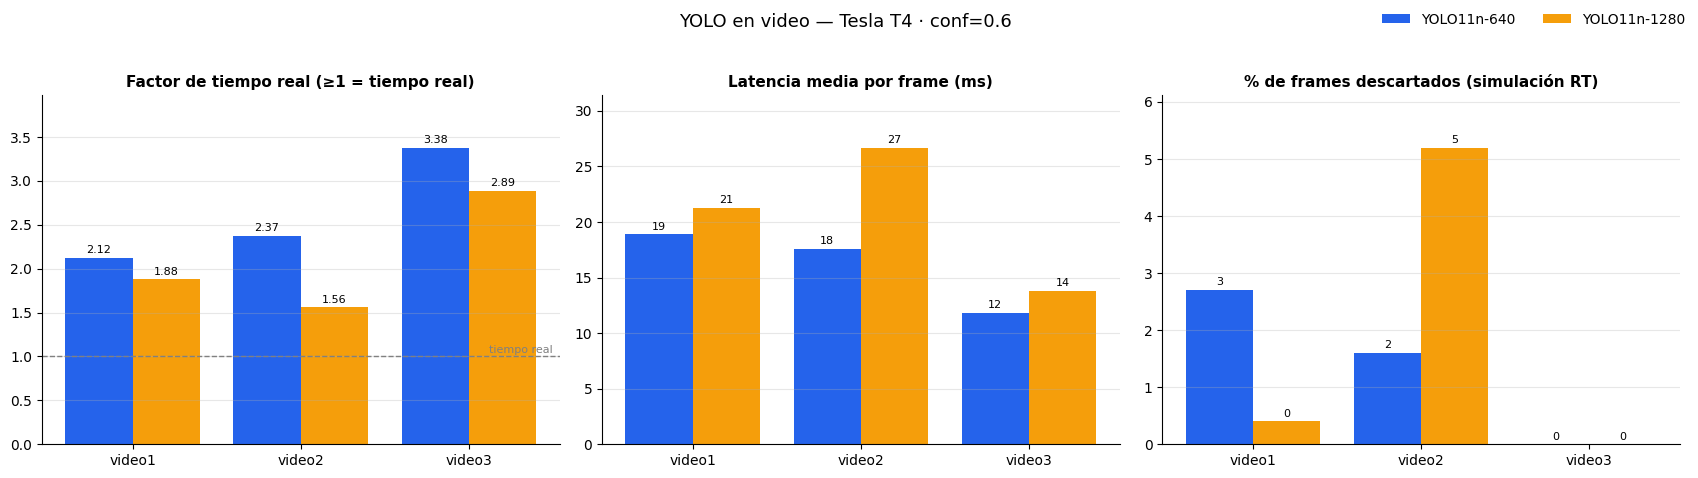

Guardado en /content: resultados_yolo.csv y grafica_yolo.png


In [ ]:
# ==============================================================
# Ítem 4 — YOLO en video / simulación de tiempo real (Colab GPU)
# Entorno de ejecución > Cambiar tipo de entorno > GPU (T4)
# ==============================================================
!pip -q install ultralytics lap

import glob, math, os, time
import cv2, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import display

# ---------------- configuración ----------------
YOLO_CARPETA = "/content"                                       # videos subidos al Colab
YOLO_VIDEOS = sorted(glob.glob(f"{YOLO_CARPETA}/video*.mp4"))   # video1.mp4, video2.mp4, video3.mp4
YOLO_MODELO = "yolo11n.pt"
YOLO_IMGSZ  = [640, 1280]  # 640 = estándar · 1280 = más detalle para objetos pequeños
YOLO_CONF   = 0.6          # MISMO umbral que el ítem 3 (UMBRAL = 0.6)
YOLO_IOU    = 0.5
# -----------------------------------------------

if not YOLO_VIDEOS:
    from google.colab import files
    print("Sube los videos:")
    YOLO_VIDEOS = [os.path.join("/content", n) for n in files.upload().keys()]

yolo_dev = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo:", torch.cuda.get_device_name(0) if yolo_dev == 0 else "CPU (¡activa la GPU!)")
yolo_model = YOLO(YOLO_MODELO)


def yolo_sync():
    if yolo_dev == 0:
        torch.cuda.synchronize()


def yolo_evaluar(ruta, imgsz):
    """Simulación de cámara en vivo con la MISMA regla del ítem 3 (reloj virtual):
    el frame i llega en i/fps; si el modelo está libre se procesa y queda ocupado
    hasta llegada + latencia; los frames que llegan mientras está ocupado se descartan."""
    cap = cv2.VideoCapture(ruta)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # calentamiento (la 1ra inferencia en GPU es lenta)
    ok, f0 = cap.read()
    for _ in range(5):
        yolo_model.predict(f0, imgsz=imgsz, conf=YOLO_CONF, iou=YOLO_IOU, device=yolo_dev, verbose=False)
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    lat, ndet, confs = [], [], []
    pos, descartados, libre_en = 0, 0, 0.0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        yolo_sync(); t0 = time.perf_counter()
        r = yolo_model.predict(frame, imgsz=imgsz, conf=YOLO_CONF, iou=YOLO_IOU,
                               device=yolo_dev, verbose=False)[0]
        yolo_sync(); dt = time.perf_counter() - t0
        lat.append(dt * 1000)
        ndet.append(len(r.boxes))
        if len(r.boxes):
            confs.extend(r.boxes.conf.cpu().numpy().tolist())

        libre_en = pos / fps + dt                        # modelo ocupado hasta aquí
        siguiente = max(pos + 1, math.ceil(libre_en * fps - 1e-9))   # 1er frame que llega con el modelo libre
        for _ in range(siguiente - pos - 1):
            if not cap.grab():
                break
            descartados += 1
        pos = siguiente
    cap.release()

    lat = np.array(lat)
    procesados = len(lat)
    factor = (1000 / lat.mean()) / fps
    return {
        "Video": os.path.splitext(os.path.basename(ruta))[0],
        "Modelo": f"YOLO11n-{imgsz}",
        "Resolución": f"{W}x{H}",
        "FPS video": round(fps, 1),
        "Latencia (ms)": round(lat.mean(), 1),
        "Latencia p95 (ms)": round(np.percentile(lat, 95), 1),
        "FPS inferencia": round(1000 / lat.mean(), 2),
        "FPS efectivo": round(procesados / (total / fps), 2),   # misma definición que el ítem 3
        "Procesados": procesados,
        "Total": total,
        "Detec./frame": round(float(np.mean(ndet)), 1),
        "Conf. media": round(float(np.mean(confs)), 3) if confs else 0.0,
        "Factor RT": round(factor, 2),
        "% descartados": round(100 * descartados / max(1, procesados + descartados), 1),
        "¿Tiempo real?": "Sí" if factor >= 1 else "No",
    }


yolo_filas = []
for v in YOLO_VIDEOS:
    for s in YOLO_IMGSZ:
        print(f"→ {os.path.basename(v)} · imgsz={s}")
        yolo_filas.append(yolo_evaluar(v, s))

df_yolo = pd.DataFrame(yolo_filas)
display(df_yolo)
df_yolo.to_csv(f"{YOLO_CARPETA}/resultados_yolo.csv", index=False)

# ---------------- gráficas ----------------
yolo_vids = df_yolo["Video"].unique()
yolo_mods = df_yolo["Modelo"].unique()
x = np.arange(len(yolo_vids))
ancho = 0.8 / len(yolo_mods)
colores = ["#2563eb", "#f59e0b", "#16a34a", "#dc2626"]

fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
metricas = [("Factor RT", "Factor de tiempo real (≥1 = tiempo real)"),
            ("Latencia (ms)", "Latencia media por frame (ms)"),
            ("% descartados", "% de frames descartados (simulación RT)")]
for ax, (col, titulo) in zip(axs, metricas):
    for i, m in enumerate(yolo_mods):
        d = df_yolo[df_yolo["Modelo"] == m].set_index("Video").reindex(yolo_vids)
        b = ax.bar(x + (i - (len(yolo_mods) - 1) / 2) * ancho, d[col], ancho,
                   label=m, color=colores[i % len(colores)])
        ax.bar_label(b, fmt="%.2f" if col == "Factor RT" else "%.0f", fontsize=8, padding=2)
    if col == "Factor RT":
        ax.axhline(1, ls="--", color="gray", lw=1)
        ax.text(len(yolo_vids) - 0.5, 1.02, "tiempo real", color="gray", fontsize=8, ha="right", va="bottom")
    ax.set_xticks(x, yolo_vids)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
for ax in axs:
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
gpu = torch.cuda.get_device_name(0) if yolo_dev == 0 else "CPU"
fig.suptitle(f"YOLO en video — {gpu} · conf={YOLO_CONF}", fontsize=13)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=len(yolo_mods), frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(f"{YOLO_CARPETA}/grafica_yolo.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Guardado en {YOLO_CARPETA}: resultados_yolo.csv y grafica_yolo.png")